In [2]:
import pandas as pd
import numpy as np

In [53]:
pd.set_option("display.max_colwidth",None)

In [3]:
df = pd.read_csv("../data/raw/zepto_v2.csv", encoding="latin1")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head(5)

,Category,name,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,outOfStock,quantity
0,Fruits & Vegetables,Onion,2500,16,3,2100,1000,False,1
1,Fruits & Vegetables,Tomato Hybrid,4200,16,3,3500,1000,False,1
2,Fruits & Vegetables,Tender Coconut,5100,15,3,4300,58,False,1
3,Fruits & Vegetables,Coriander Leaves,2000,15,3,1700,100,False,100
4,Fruits & Vegetables,Ladies Finger,1400,14,3,1200,250,False,250


In [5]:
df.shape

(3732, 9)

In [6]:
df.columns.tolist()

['Category',
 'name',
 'mrp',
 'discountPercent',
 'availableQuantity',
 'discountedSellingPrice',
 'weightInGms',
 'outOfStock',
 'quantity']

In [7]:
df.dtypes

Category                  object
name                      object
mrp                        int64
discountPercent            int64
availableQuantity          int64
discountedSellingPrice     int64
weightInGms                int64
outOfStock                  bool
quantity                   int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3732 entries, 0 to 3731
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Category                3732 non-null   object
 1   name                    3732 non-null   object
 2   mrp                     3732 non-null   int64 
 3   discountPercent         3732 non-null   int64 
 4   availableQuantity       3732 non-null   int64 
 5   discountedSellingPrice  3732 non-null   int64 
 6   weightInGms             3732 non-null   int64 
 7   outOfStock              3732 non-null   bool  
 8   quantity                3732 non-null   int64 
dtypes: bool(1), int64(6), object(2)
memory usage: 237.0+ KB


In [9]:
df['mrp']=df['mrp']/100
df['discountedSellingPrice']=df['discountedSellingPrice']/100

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
mrp,3732.0,156.801179,160.888076,0.0,60.0,110.0,200.0,2600.0
discountPercent,3732.0,7.617095,9.211733,0.0,0.0,6.0,10.0,51.0
availableQuantity,3732.0,4.008574,2.203511,0.0,2.0,5.0,6.0,6.0
discountedSellingPrice,3732.0,141.928349,138.507263,0.0,55.0,104.0,184.0,1399.0
weightInGms,3732.0,387.843783,678.096509,0.0,100.0,225.0,450.0,10000.0
quantity,3732.0,213.270900,194.730976,0.0,50.0,186.0,340.0,1500.0


In [11]:
df.duplicated().sum()

np.int64(2)

In [12]:
df[df.duplicated(keep=False)]

,Category,name,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,outOfStock,quantity
2908,Personal Care,Listerine Cool Mint Mouthwash - Mild Taste,150.0,10,6,135.0,250,False,250
2946,Personal Care,Listerine Cool Mint Mouthwash - Mild Taste,150.0,10,6,135.0,250,False,250
3252,Paan Corner,Listerine Cool Mint Mouthwash - Mild Taste,150.0,10,6,135.0,250,False,250
3290,Paan Corner,Listerine Cool Mint Mouthwash - Mild Taste,150.0,10,6,135.0,250,False,250


In [13]:
df=df.drop_duplicates().reset_index(drop=True)

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df[df['name'].duplicated(keep=False)].sort_values('name')

,Category,name,mrp,discountPercent,availableQuantity,discountedSellingPrice,weightInGms,outOfStock,quantity
272,Cooking Essentials,"""Maggi Magic Cubes, Vegetarian Masala (Free 2 ...",35.0,2,6,34.0,48,False,48
786,Munchies,"""Maggi Magic Cubes, Vegetarian Masala (Free 2 ...",35.0,2,6,34.0,48,False,48
371,Cooking Essentials,"""Maggi Magic Cubes, Vegetarian Masala""",35.0,2,1,34.0,40,False,40
885,Munchies,"""Maggi Magic Cubes, Vegetarian Masala""",35.0,2,1,34.0,40,False,40
208,Cooking Essentials,24 Mantra Bura Sugar (Demerara),80.0,10,6,72.0,500,False,500
...,...,...,...,...,...,...,...,...,...
1268,Beverages,iD Natural Paneer,105.0,5,6,99.0,200,False,200
1139,"Dairy, Bread & Batter",iD Natural Paneer,105.0,5,6,99.0,200,False,200
1382,Packaged Food,iD Wheat Lachha Paratha,80.0,12,6,70.0,400,False,400
2158,Chocolates & Candies,iD Wheat Lachha Paratha,80.0,12,6,70.0,400,False,400


In [16]:
df.groupby('name')['Category'].nunique().sort_values(ascending=False).head(10)

name
iD Idli & Dosa Batter                            7
Godrej Yummiez Chicken Punjabi Tikka             6
Zorabian Chicken Kheema Parathas                 6
Godrej Yummiez Chilli Chicken Sausages           6
Godrej Yummiez Chicken Breakfast Salami          6
Zorabian Chicken Smoked Ham                      6
Yummiez Chicken Garlic Fingers Pouch             6
Godrej Yummiez Chicken Nuggets                   6
Chings Secret Chowmein Hakka Noodles Masala     5
Saffola Yummy Masala Noodles                     5
Name: Category, dtype: int64

In [17]:
for col in df.columns:
    print(f"\nColumn:{col} ->",df[col].nunique())


Column:Category -> 14

Column:name -> 1681

Column:mrp -> 266

Column:discountPercent -> 42

Column:availableQuantity -> 7

Column:discountedSellingPrice -> 350

Column:weightInGms -> 158

Column:outOfStock -> 2

Column:quantity -> 143


In [18]:
df['Category'].unique()

array(['Fruits & Vegetables', 'Cooking Essentials', 'Munchies',
       'Dairy, Bread & Batter', 'Beverages', 'Packaged Food',
       'Ice Cream & Desserts', 'Chocolates & Candies',
       'Meats, Fish & Eggs', 'Biscuits', 'Personal Care', 'Paan Corner',
       'Home & Cleaning', 'Health & Hygiene'], dtype=object)

In [19]:
df['Category'].value_counts(dropna=False)

Category
Cooking Essentials       514
Munchies                 514
Packaged Food            388
Ice Cream & Desserts     388
Chocolates & Candies     388
Personal Care            343
Paan Corner              343
Home & Cleaning          194
Biscuits                 147
Dairy, Bread & Batter    129
Beverages                129
Health & Hygiene          97
Fruits & Vegetables       93
Meats, Fish & Eggs        63
Name: count, dtype: int64

### CALCULATE AVERAGE DISCOUNT BY CATEGORY 


In [20]:
avgCategoryDiscount=(df.groupby('Category')['discountPercent'].mean().sort_values(ascending=False))
print(avgCategoryDiscount)

Category
Fruits & Vegetables      15.462366
Meats, Fish & Eggs       11.031746
Chocolates & Candies      8.324742
Ice Cream & Desserts      8.324742
Packaged Food             8.324742
Biscuits                  8.244898
Health & Hygiene          8.051546
Cooking Essentials        7.163424
Munchies                  7.163424
Beverages                 7.155039
Dairy, Bread & Batter     7.155039
Paan Corner               6.239067
Personal Care             6.239067
Home & Cleaning           5.675258
Name: discountPercent, dtype: float64


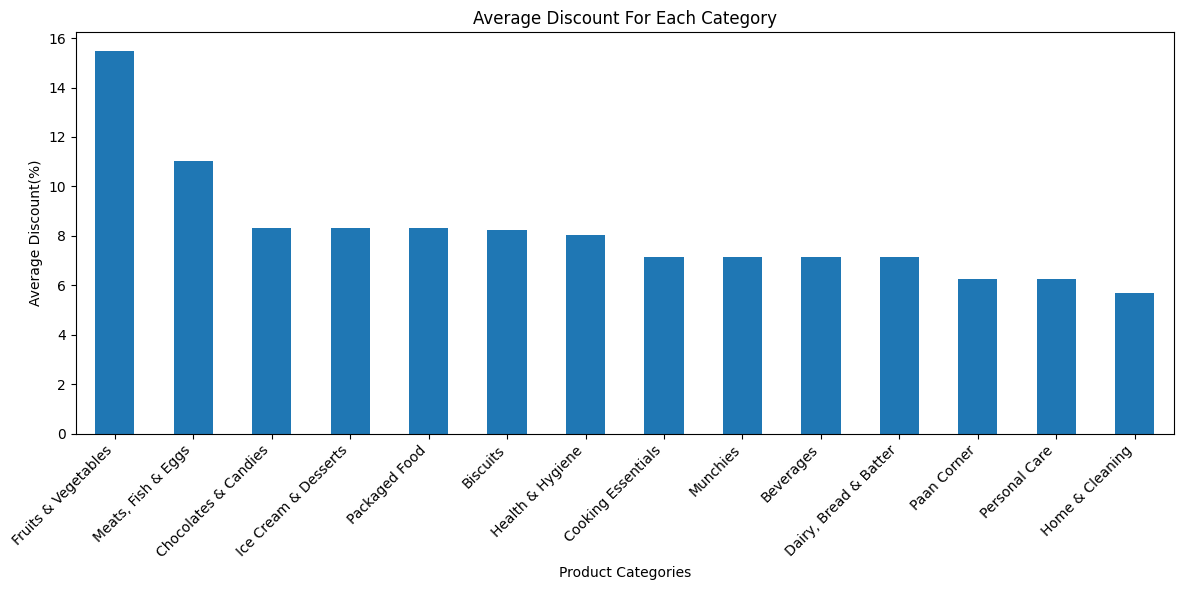

In [21]:
from pathlib import Path

visualization_dir = Path("../visualizations")
visualization_dir.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
avgCategoryDiscount.plot(kind='bar',figsize=(12,6))
plt.title("Average Discount For Each Category")
plt.xlabel("Product Categories")
plt.ylabel("Average Discount(%)")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.savefig(visualization_dir / "01_average_discount_for_each_category.png", dpi=300, bbox_inches="tight")
plt.show()


In [22]:
overallDiscount=df['discountPercent'].mean()
print(f"Overall average discount:{overallDiscount: .2f}%")

Overall average discount: 7.62%


### FIND WHICH CATEGORIES HAVE THE HIGHEST AVGERAGE SELLING PRICE?

In [23]:
avgSellingPrice=df.groupby("Category")['discountedSellingPrice'].mean().sort_values(ascending=False)
print(avgSellingPrice)

Category
Paan Corner              189.897959
Personal Care            189.897959
Meats, Fish & Eggs       164.095238
Health & Hygiene         145.855670
Home & Cleaning          141.448454
Chocolates & Candies     141.077320
Ice Cream & Desserts     141.077320
Packaged Food            141.077320
Cooking Essentials       140.826848
Munchies                 140.826848
Beverages                103.728682
Dairy, Bread & Batter    103.728682
Biscuits                  52.779592
Fruits & Vegetables       39.838710
Name: discountedSellingPrice, dtype: float64


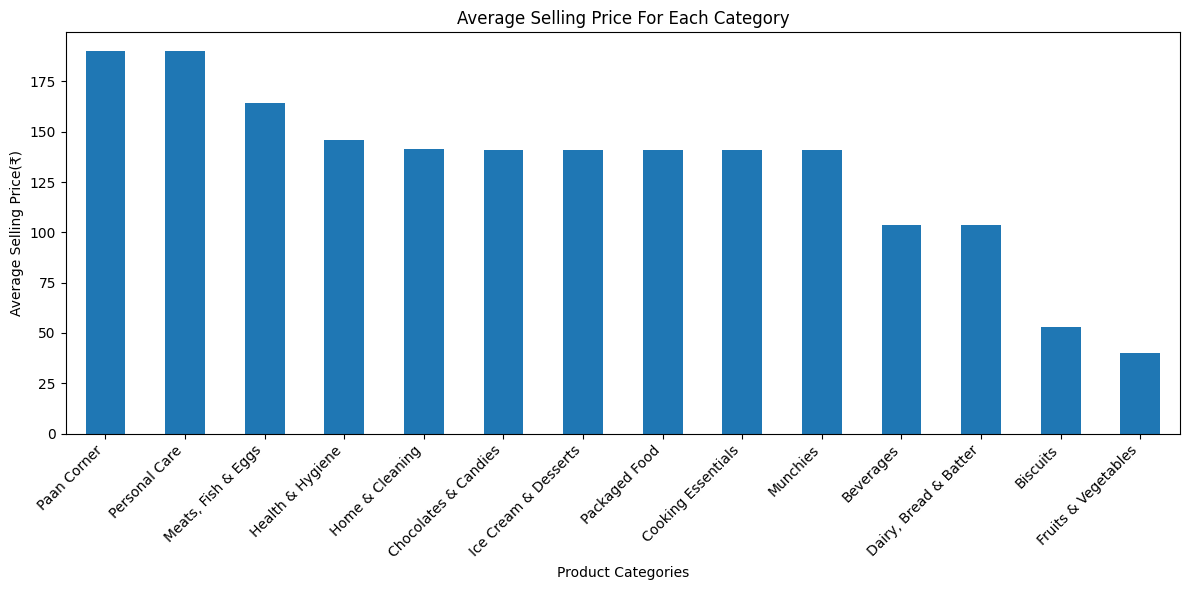

In [24]:
avgSellingPrice.plot(kind='bar',figsize=(12,6))
plt.title("Average Selling Price For Each Category")
plt.xlabel("Product Categories")
plt.ylabel("Average Selling Price(₹)")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.savefig(visualization_dir / "02_average_selling_price_for_each_category.png", dpi=300, bbox_inches="tight")
plt.show()


### COMPARE MRP WITH SELLING PRICE

In [25]:
priceComparison=(df.groupby("Category").agg(
          average_mrp=("mrp","mean"),
          averageSellingPrice=("discountedSellingPrice","mean")).sort_values("averageSellingPrice", ascending=False))
print(priceComparison.round(2))

                       average_mrp  averageSellingPrice
Category                                               
Paan Corner                 207.29               189.90
Personal Care               207.29               189.90
Meats, Fish & Eggs          187.29               164.10
Health & Hygiene            159.18               145.86
Home & Cleaning             152.15               141.45
Chocolates & Candies        155.73               141.08
Ice Cream & Desserts        155.73               141.08
Packaged Food               155.73               141.08
Cooking Essentials          156.54               140.83
Munchies                    156.54               140.83
Beverages                   118.71               103.73
Dairy, Bread & Batter       118.71               103.73
Biscuits                     59.49                52.78
Fruits & Vegetables          47.01                39.84


### COUNT PRODUCTS THAT ARE IN STOCK VERSUS OUT OF STOCK 

In [27]:
df["outOfStock"].value_counts()

outOfStock
False    3277
True      453
Name: count, dtype: int64

### CALCULATE STOCK AVAILABILTY PERCENTAGE

In [28]:
stockPercentage=(df["outOfStock"].value_counts(normalize=True)*100)
print(stockPercentage.round(2))

outOfStock
False    87.86
True     12.14
Name: proportion, dtype: float64


### IDENTIFY CATEGORIES WITH MOST OUT_OF_STOCK PRODUCTS

In [29]:
outOfStockCategories=(df[df["outOfStock"]==True].groupby("Category").size().sort_values(ascending=False))
print(outOfStockCategories)

Category
Cooking Essentials       64
Munchies                 64
Chocolates & Candies     45
Ice Cream & Desserts     45
Packaged Food            45
Biscuits                 42
Beverages                28
Dairy, Bread & Batter    28
Paan Corner              21
Personal Care            21
Home & Cleaning          19
Health & Hygiene         13
Meats, Fish & Eggs       12
Fruits & Vegetables       6
dtype: int64


### CALCULATE THE OUT OF STOCK RATE BY CATEGORY

In [30]:
categoryOutOfStockRate=df.groupby("Category")["outOfStock"].mean().mul(100).sort_values(ascending=False)
print(categoryOutOfStockRate.round(2))

Category
Biscuits                 28.57
Beverages                21.71
Dairy, Bread & Batter    21.71
Meats, Fish & Eggs       19.05
Health & Hygiene         13.40
Cooking Essentials       12.45
Munchies                 12.45
Chocolates & Candies     11.60
Ice Cream & Desserts     11.60
Packaged Food            11.60
Home & Cleaning           9.79
Fruits & Vegetables       6.45
Paan Corner               6.12
Personal Care             6.12
Name: outOfStock, dtype: float64


### CORRELATION BETWEEN DISCOUNTPERCENT & SELLING PRICE

In [31]:
correlation=df[["discountPercent","discountedSellingPrice"]].corr()
print(correlation)

                        discountPercent  discountedSellingPrice
discountPercent                1.000000                0.037876
discountedSellingPrice         0.037876                1.000000


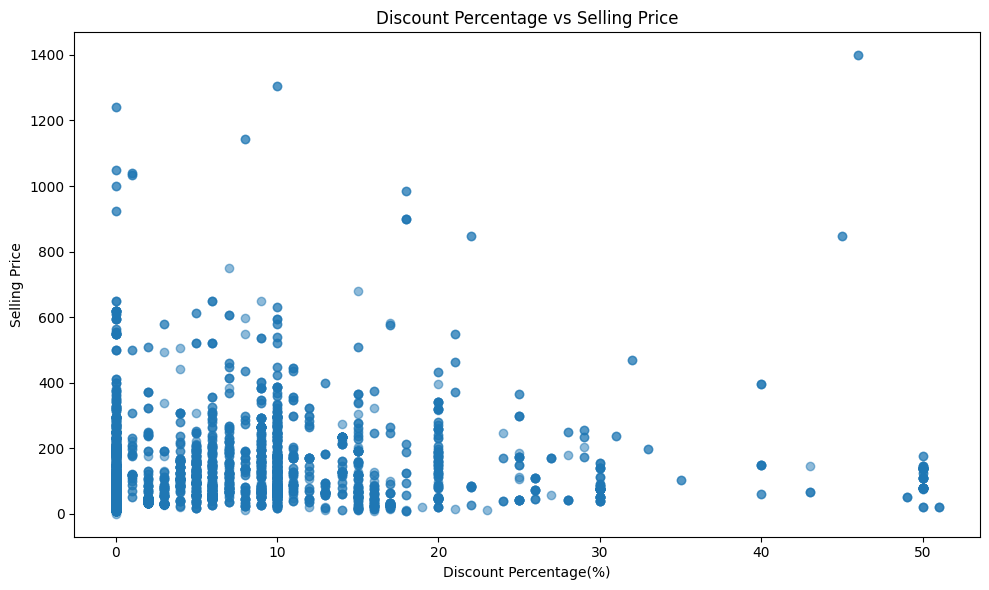

In [32]:
plt.figure(figsize=(10,6))
plt.scatter(df["discountPercent"],df["discountedSellingPrice"],alpha=0.5)
plt.title("Discount Percentage vs Selling Price")
plt.xlabel("Discount Percentage(%)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.savefig(visualization_dir / "03_discount_percentage_vs_selling_price.png", dpi=300, bbox_inches="tight")
plt.show()


In [33]:
categoryAnalysis=(df.groupby("Category").agg(avgDiscountPercent=("discountPercent","mean"),
                                             avgSellingPrice=("discountedSellingPrice","mean"),productCount=("name","count"))
                                             .sort_values("avgDiscountPercent",ascending=False))
print(categoryAnalysis)

                       avgDiscountPercent  avgSellingPrice  productCount
Category                                                                
Fruits & Vegetables             15.462366        39.838710            93
Meats, Fish & Eggs              11.031746       164.095238            63
Chocolates & Candies             8.324742       141.077320           388
Ice Cream & Desserts             8.324742       141.077320           388
Packaged Food                    8.324742       141.077320           388
Biscuits                         8.244898        52.779592           147
Health & Hygiene                 8.051546       145.855670            97
Cooking Essentials               7.163424       140.826848           514
Munchies                         7.163424       140.826848           514
Beverages                        7.155039       103.728682           129
Dairy, Bread & Batter            7.155039       103.728682           129
Paan Corner                      6.239067       189

### FIND PRODUCTS OFFERING THE BIGGEST DISCOUNTS

In [41]:
topDiscountProducts=df.nlargest(10,"discountPercent")[["Category","name","mrp","discountedSellingPrice","discountPercent"]]
print(topDiscountProducts)

                Category                                            name  \
2608            Biscuits                    Dukes Waffy Chocolate Wafers   
2615            Biscuits                       Dukes Waffy Orange Wafers   
2619            Biscuits                   Dukes Waffy Strawberry Wafers   
198   Cooking Essentials           Chef's Basket Durum Wheat Elbow Pasta   
217   Cooking Essentials         Chef's Basket Durum Wheat Fusilli Pasta   
278   Cooking Essentials  Ceres Foods Fish Mustard Instant Liquid Masala   
395   Cooking Essentials     Ceres Foods Laal Maas Instant Liquid Masala   
490   Cooking Essentials  Ceres Foods Nalli Nihari Instant Liquid Masala   
593   Cooking Essentials           Chef's Basket Durum Wheat Penne Pasta   
712             Munchies           Chef's Basket Durum Wheat Elbow Pasta   

        mrp  discountedSellingPrice  discountPercent  
2608   45.0                    22.0               51  
2615   45.0                    22.0               51 

### WHICH PRODUCTS RECEIVE THE BIGGEST DISCOUNT

In [42]:
df["discountAmount"]=df["mrp"]-df["discountedSellingPrice"]
top_Discount_Products=(df[["Category","name","mrp","discountedSellingPrice","discountPercent","discountAmount"]].sort_values("discountAmount",ascending=False).head(10))
print(top_Discount_Products)

                  Category                                               name  \
517     Cooking Essentials               Borges Extra Light Olive Oil Bottle    
1031              Munchies               Borges Extra Light Olive Oil Bottle    
3015         Personal Care                              Pampers Pants - Large   
3358           Paan Corner                              Pampers Pants - Large   
1935  Ice Cream & Desserts                    Kelloggs Chocos - Moons & Stars   
2323  Chocolates & Candies                    Kelloggs Chocos - Moons & Stars   
1547         Packaged Food                    Kelloggs Chocos - Moons & Stars   
3365           Paan Corner  Pampers Active Baby Diapers New Born Extra Small    
3022         Personal Care  Pampers Active Baby Diapers New Born Extra Small    
768               Munchies              Popular Essentials Californian Almond   

         mrp  discountedSellingPrice  discountPercent  discountAmount  
517   2600.0                  1399.0

### WITH IN EACH CATEGORY FIND TOP 3 PRODUCTS HAVING HIGHEST DISCOUNT PERCENTAGES

In [57]:
top_3_discounted_products=(df.sort_values("discountPercent",ascending=False).groupby("Category")).head(3)
print(top_3_discounted_products[["Category","name","discountPercent"]])

                   Category  \
2619               Biscuits   
2608               Biscuits   
2615               Biscuits   
1191  Dairy, Bread & Batter   
1195  Dairy, Bread & Batter   
1197  Dairy, Bread & Batter   
1643          Packaged Food   
1326              Beverages   
1303              Beverages   
2092   Ice Cream & Desserts   
198      Cooking Essentials   
1320              Beverages   
2135   Ice Cream & Desserts   
2031   Ice Cream & Desserts   
1431          Packaged Food   
1443          Packaged Food   
217      Cooking Essentials   
278      Cooking Essentials   
1107               Munchies   
792                Munchies   
3717       Health & Hygiene   
2419   Chocolates & Candies   
2480   Chocolates & Candies   
2385   Chocolates & Candies   
2564     Meats, Fish & Eggs   
3634       Health & Hygiene   
3633       Health & Hygiene   
712                Munchies   
2591     Meats, Fish & Eggs   
2586     Meats, Fish & Eggs   
3358            Paan Corner   
3015    

### WHICH PRODUCT CATEGORIES GENERATE THE HIGHEST POTENTIAL REVENUE

In [48]:
df["inventoryValue"]=(df["discountedSellingPrice"]*df["availableQuantity"])
categoryInventory=(df.groupby("Category").agg(productCount=("name","count"),totalInventoryValue=("inventoryValue","sum"),avgInventoryValue=("inventoryValue","mean")).sort_values(by="totalInventoryValue",ascending=False))
print(categoryInventory.round(2))

                       productCount  totalInventoryValue  avgInventoryValue
Category                                                                   
Cooking Essentials              514             337369.0             656.36
Munchies                        514             337369.0             656.36
Paan Corner                     343             270039.0             787.29
Personal Care                   343             270039.0             787.29
Chocolates & Candies            388             224385.0             578.31
Ice Cream & Desserts            388             224385.0             578.31
Packaged Food                   388             224385.0             578.31
Home & Cleaning                 194             122661.0             632.27
Health & Hygiene                 97              64180.0             661.65
Beverages                       129              55051.0             426.75
Dairy, Bread & Batter           129              55051.0             426.75
Biscuits    

In [75]:
top_5_inventory=categoryInventory.head(5)
print(top_5_inventory[["totalInventoryValue"]])

                      totalInventoryValue
Category                                 
Cooking Essentials               337369.0
Munchies                         337369.0
Paan Corner                      270039.0
Personal Care                    270039.0
Chocolates & Candies             224385.0


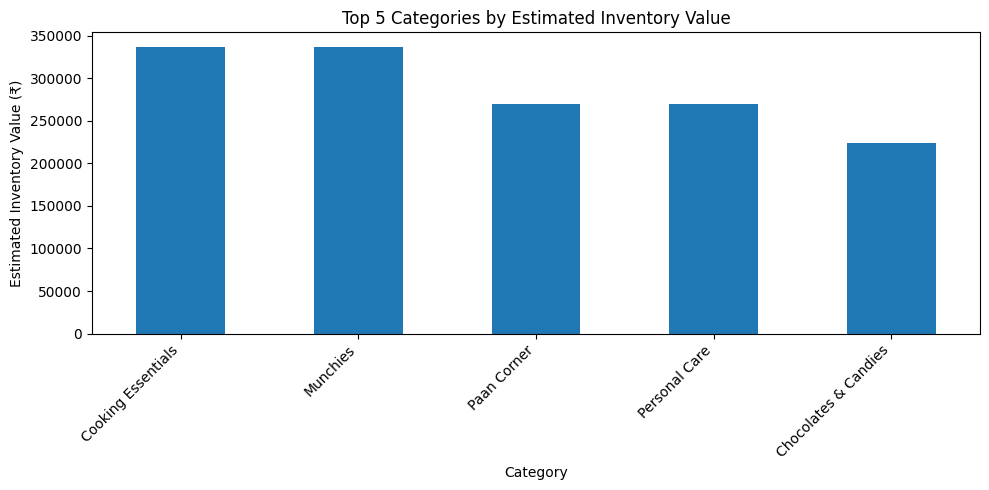

In [78]:
top_5_inventory["totalInventoryValue"].plot(kind="bar",figsize=(10, 5))
plt.title("Top 5 Categories by Estimated Inventory Value")
plt.xlabel("Category")
plt.ylabel("Estimated Inventory Value (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(visualization_dir / "04_top_5_categories_by_estimated_inventory_value.png", dpi=300, bbox_inches="tight")
plt.show()


In [56]:
topProducts=(df.sort_values(by=["Category","discountedSellingPrice"],ascending=[True,False]).groupby("Category").head(3))
print(topProducts[["Category","name","discountedSellingPrice"]])

                   Category  \
1336              Beverages   
1294              Beverages   
1349              Beverages   
2709               Biscuits   
2669               Biscuits   
2744               Biscuits   
2287   Chocolates & Candies   
2445   Chocolates & Candies   
2391   Chocolates & Candies   
517      Cooking Essentials   
363      Cooking Essentials   
144      Cooking Essentials   
1207  Dairy, Bread & Batter   
1165  Dairy, Bread & Batter   
1220  Dairy, Bread & Batter   
46      Fruits & Vegetables   
92      Fruits & Vegetables   
43      Fruits & Vegetables   
3708       Health & Hygiene   
3666       Health & Hygiene   
3706       Health & Hygiene   
3543        Home & Cleaning   
3536        Home & Cleaning   
3554        Home & Cleaning   
1899   Ice Cream & Desserts   
2057   Ice Cream & Desserts   
2003   Ice Cream & Desserts   
2584     Meats, Fish & Eggs   
2585     Meats, Fish & Eggs   
2560     Meats, Fish & Eggs   
1031               Munchies   
877     

### DOES PRODUCT AVALIABILITY RELATE TO SELLING PRICE?

In [59]:
stockPriceAnalysis=(df.groupby("outOfStock").agg(avgSellingPrice=("discountedSellingPrice","mean"),avgMRP=("mrp","mean"),productCount=("name","count")))
print(stockPriceAnalysis.round(2))

            avgSellingPrice  avgMRP  productCount
outOfStock                                       
False                149.65  165.65          3277
True                  86.13   92.79           453


### CALCULATE OUT-OF-STOCK RATES BY DISCOUNY RANGE

In [83]:
df["discountRange"]=pd.cut(df["discountPercent"],bins=[-1,10,20,30,40,50,100],labels=["0-10%","10-20%","20-30%","30-40%","40-50%","50-100%"],include_lowest=True)
discountStockAnalysis=(df.groupby("discountRange",observed=False).agg(outOfStockRate=("outOfStock","mean"),productCount=("name","count")))
discountStockAnalysis["outOfStockRate"].mul(100)
print(discountStockAnalysis.round(2))


               outOfStockRate  productCount
discountRange                              
0-10%                    0.14          2918
10-20%                   0.07           579
20-30%                   0.03           146
30-40%                   0.11            18
40-50%                   0.14            66
50-100%                  0.00             3


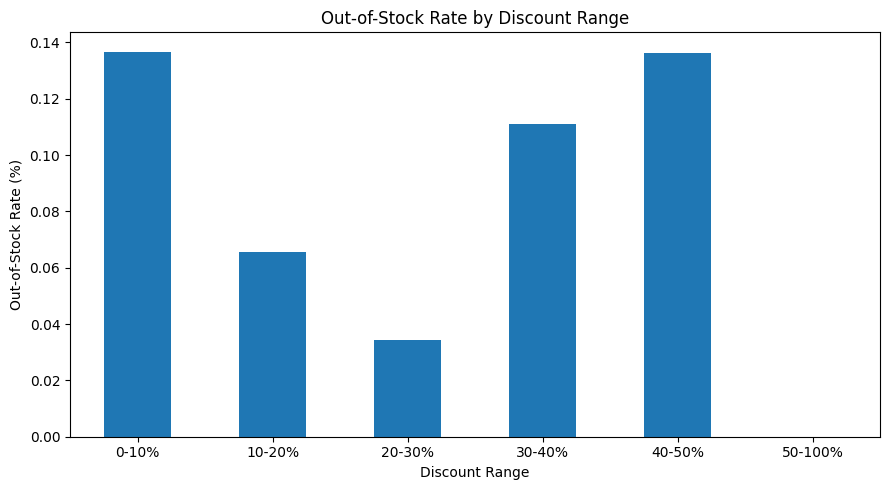

In [85]:
discountStockAnalysis["outOfStockRate"].plot(kind="bar",figsize=(9, 5))
plt.title("Out-of-Stock Rate by Discount Range")
plt.xlabel("Discount Range")
plt.ylabel("Out-of-Stock Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(visualization_dir / "05_out_of_stock_rate_by_discount_range.png", dpi=300, bbox_inches="tight")
plt.show()


### CALCULATE THE PERCENTAGE OF OUT-OF-STOCK PRODUCTS BY PRICE RANGE

In [63]:
df["priceRange"]=pd.cut(df["discountedSellingPrice"],bins=[0,100,300,500,700,900,float('inf')],labels=["under ₹100","₹100-₹300","₹300-₹500","₹500-₹700","700-900","Above ₹1000"],include_lowest=True)
priceStockAnalysis=(df.groupby("priceRange",observed=False)['outOfStock'].mean().mul(100))
print(priceStockAnalysis.round(2))

priceRange
under ₹100     17.66
₹100-₹300       7.73
₹300-₹500       1.06
₹500-₹700       2.41
700-900         0.00
Above ₹1000     0.00
Name: outOfStock, dtype: float64


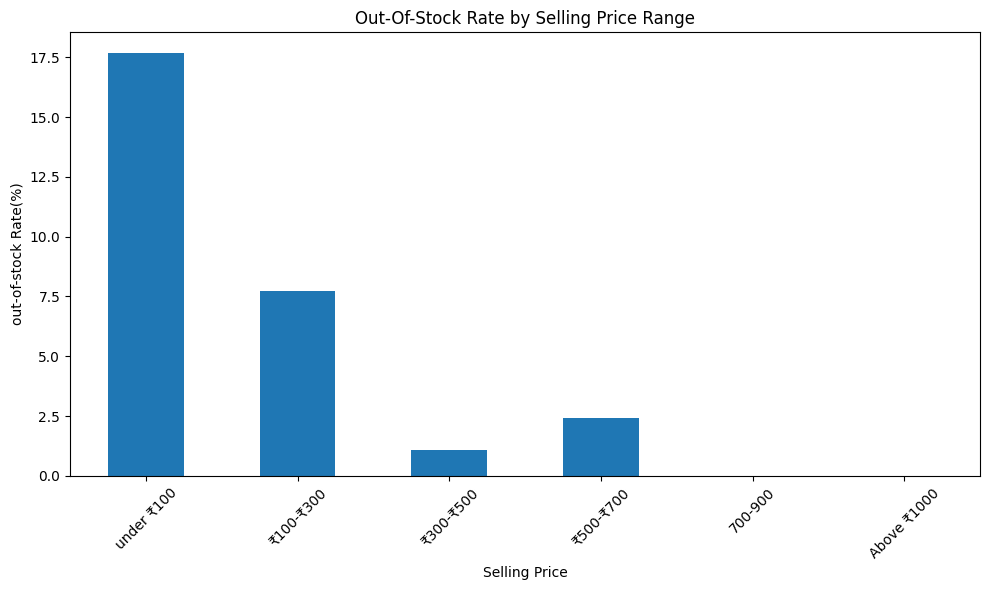

In [64]:
plt.figure(figsize=(10,6))
priceStockAnalysis.plot(kind='bar')
plt.title("Out-Of-Stock Rate by Selling Price Range")
plt.xlabel("Selling Price")
plt.ylabel("out-of-stock Rate(%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_dir / "06_out_of_stock_rate_by_selling_price_range.png", dpi=300, bbox_inches="tight")
plt.show()


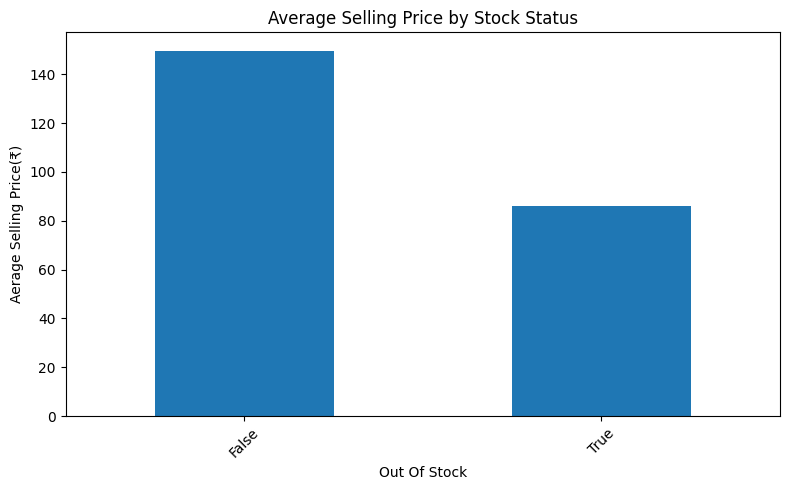

In [67]:
stockPriceAnalysis["avgSellingPrice"].plot(kind='bar',figsize=(8,5))
plt.title("Average Selling Price by Stock Status")
plt.xlabel("Out Of Stock")
plt.ylabel("Aerage Selling Price(₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(visualization_dir / "07_average_selling_price_by_stock_status.png", dpi=300, bbox_inches="tight")
plt.show()


### IDENTIFY PRODUCTS WITH HIGH DISCOUNT AND LOW AVALIABILITY

In [89]:
highDiscountLowStock=df[(df['discountPercent']>=30) & (df['availableQuantity']<=10) & (df['outOfStock']==False)]
highDiscountLowStock=highDiscountLowStock.sort_values(by="discountPercent",ascending=False)
print("Products Found:",len(highDiscountLowStock))

Products Found: 132


### CALCULATE AVERAGE SELLING PRICE BY CATEGORY

In [69]:
categoryPriceAnalysis=(df.groupby("Category").agg(avgSellingPrice=("discountedSellingPrice","mean"),maxSellingPrice=("discountedSellingPrice","max"),
                                                  minSellingPrice=("discountedSellingPrice","min")).sort_values(by="avgSellingPrice",ascending=False))
print(categoryPriceAnalysis.round(2))

                       avgSellingPrice  maxSellingPrice  minSellingPrice
Category                                                                
Paan Corner                     189.90            899.0             10.0
Personal Care                   189.90            899.0             10.0
Meats, Fish & Eggs              164.10            495.0             10.0
Health & Hygiene                145.86            555.0             20.0
Home & Cleaning                 141.45            750.0              0.0
Chocolates & Candies            141.08            650.0             10.0
Ice Cream & Desserts            141.08            650.0             10.0
Packaged Food                   141.08            650.0             10.0
Cooking Essentials              140.83           1399.0             10.0
Munchies                        140.83           1399.0             10.0
Beverages                       103.73            372.0             15.0
Dairy, Bread & Batter           103.73            3

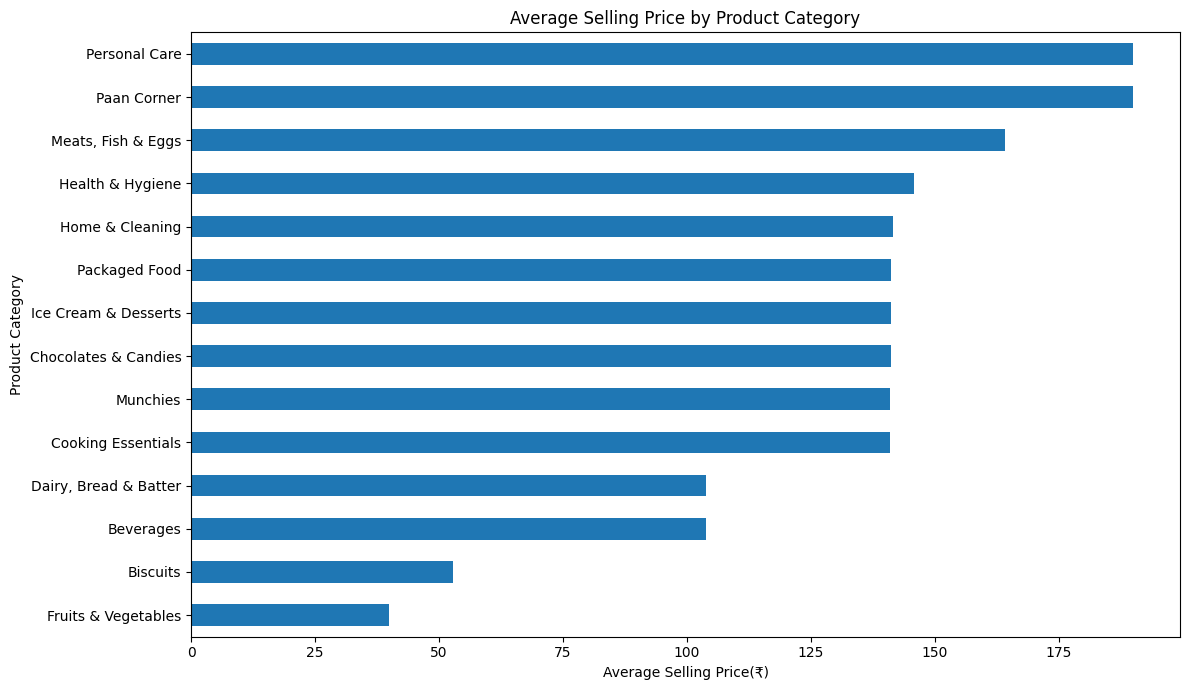

In [70]:
plt.figure(figsize=(12,7))
categoryPriceAnalysis["avgSellingPrice"].sort_values().plot(kind='barh')
plt.title("Average Selling Price by Product Category")
plt.xlabel("Average Selling Price(₹)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.savefig(visualization_dir / "08_average_selling_price_by_product_category.png", dpi=300, bbox_inches="tight")
plt.show()


### CALCULATE AVERAGE DISCOUNT PERCENTAGE BY CATEGORY

In [ ]:
categoryDiscountAnalysis=(df.groupby("Category").agg(avgDiscountPercent=("discountPercent","mean"),avgSellingPrice=("discountedSellingPrice","mean"),
                                                     avgMRP=("mrp","mean")).sort_values(by="avgDiscountPercent",ascending=False))
print(categoryDiscountAnalysis.round(2))

                       avgDiscountPercent  avgSellingPrice  avgMRP
Category                                                          
Fruits & Vegetables                 15.46            39.84   47.01
Meats, Fish & Eggs                  11.03           164.10  187.29
Chocolates & Candies                 8.32           141.08  155.73
Ice Cream & Desserts                 8.32           141.08  155.73
Packaged Food                        8.32           141.08  155.73
Biscuits                             8.24            52.78   59.49
Health & Hygiene                     8.05           145.86  159.18
Cooking Essentials                   7.16           140.83  156.54
Munchies                             7.16           140.83  156.54
Beverages                            7.16           103.73  118.71
Dairy, Bread & Batter                7.16           103.73  118.71
Paan Corner                          6.24           189.90  207.29
Personal Care                        6.24           189.90  20

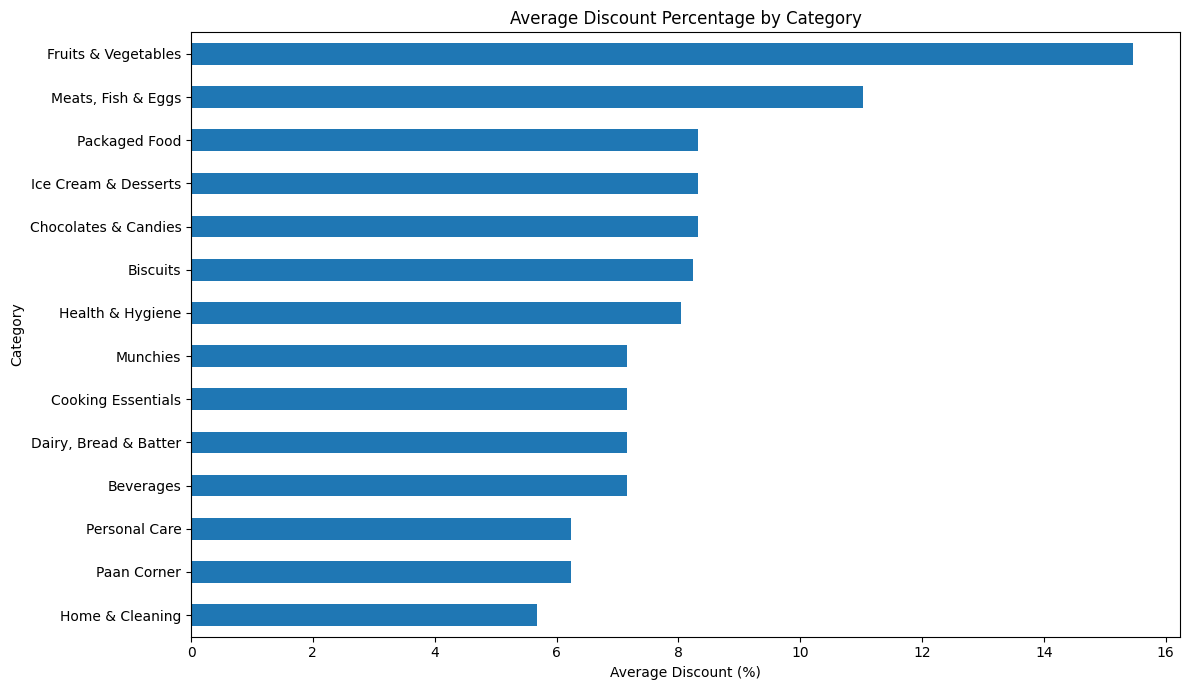

In [ ]:
plt.figure(figsize=(12, 7))
categoryDiscountAnalysis["avgDiscountPercent"].sort_values().plot(kind="barh")
plt.title("Average Discount Percentage by Category")
plt.xlabel("Average Discount (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(visualization_dir / "09_average_discount_percentage_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


# Detect selling price outliers


In [74]:
Q1=df["discountedSellingPrice"].quantile(0.25)
Q3=df["discountedSellingPrice"].quantile(0.75)
IQR = Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
# Filter outliers
price_outliers = df[
    (df["discountedSellingPrice"] < lower_bound) |
    (df["discountedSellingPrice"] > upper_bound)]
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("\nNumber of price outliers:", len(price_outliers))
price_outliers[["Category", "name", "mrp", "discountedSellingPrice"]].sort_values(by="discountedSellingPrice",ascending=False).head(10)

Q1: 55.0
Q3: 184.0
IQR: 129.0
Lower bound: -138.5
Upper bound: 377.5

Number of price outliers: 176


,Category,name,mrp,discountedSellingPrice
517,Cooking Essentials,Borges Extra Light Olive Oil Bottle,2600.0,1399.0
1031,Munchies,Borges Extra Light Olive Oil Bottle,2600.0,1399.0
877,Munchies,Praakritik Natural Desi Gir Cow A2 Ghee,1450.0,1305.0
363,Cooking Essentials,Praakritik Natural Desi Gir Cow A2 Ghee,1450.0,1305.0
658,Munchies,Saffola Gold (Jar),1240.0,1240.0
144,Cooking Essentials,Saffola Gold (Jar),1240.0,1240.0
121,Cooking Essentials,Dhara Kachi Ghani Mustard Oil Jar,1250.0,1143.0
635,Munchies,Dhara Kachi Ghani Mustard Oil Jar,1250.0,1143.0
511,Cooking Essentials,Dhara Filtered Groundnut Oil (Jar),1050.0,1050.0
1025,Munchies,Dhara Filtered Groundnut Oil (Jar),1050.0,1050.0


<Figure size 1400x700 with 0 Axes>

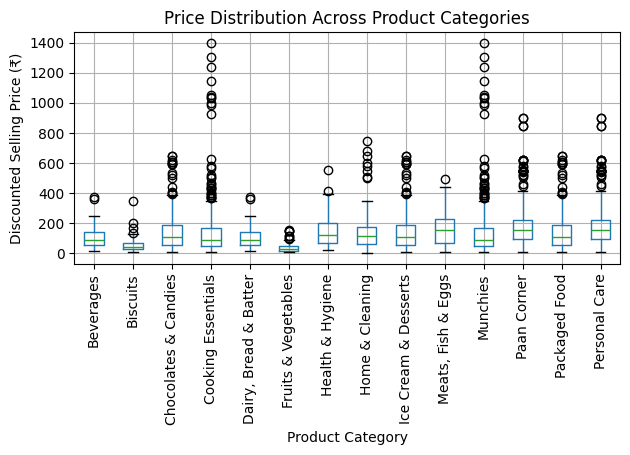

In [91]:
plt.figure(figsize=(14, 7))
df.boxplot(column="discountedSellingPrice",by="Category",rot=90)
plt.title("Price Distribution Across Product Categories")
plt.suptitle("")
plt.xlabel("Product Category")
plt.ylabel("Discounted Selling Price (₹)")
plt.tight_layout()
plt.savefig(visualization_dir / "10_price_distribution_across_product_categories.png", dpi=300, bbox_inches="tight")
plt.show()


# FIND THE CORREALTION BETWEEN NUMERICAL VALUES 

In [92]:
numeric_columns = [
    "mrp",
    "discountPercent",
    "availableQuantity",
    "discountedSellingPrice",
    "weightInGms",
    "quantity"
]
correlation_matrix = df[numeric_columns].corr()
print(correlation_matrix.round(2))

                         mrp  discountPercent  availableQuantity  \
mrp                     1.00             0.17               0.11   
discountPercent         0.17             1.00               0.09   
availableQuantity       0.11             0.09               1.00   
discountedSellingPrice  0.97             0.04               0.11   
weightInGms             0.44             0.01               0.04   
quantity                0.08             0.02               0.01   

                        discountedSellingPrice  weightInGms  quantity  
mrp                                       0.97         0.44      0.08  
discountPercent                           0.04         0.01      0.02  
availableQuantity                         0.11         0.04      0.01  
discountedSellingPrice                    1.00         0.47      0.09  
weightInGms                               0.47         1.00      0.01  
quantity                                  0.09         0.01      1.00  


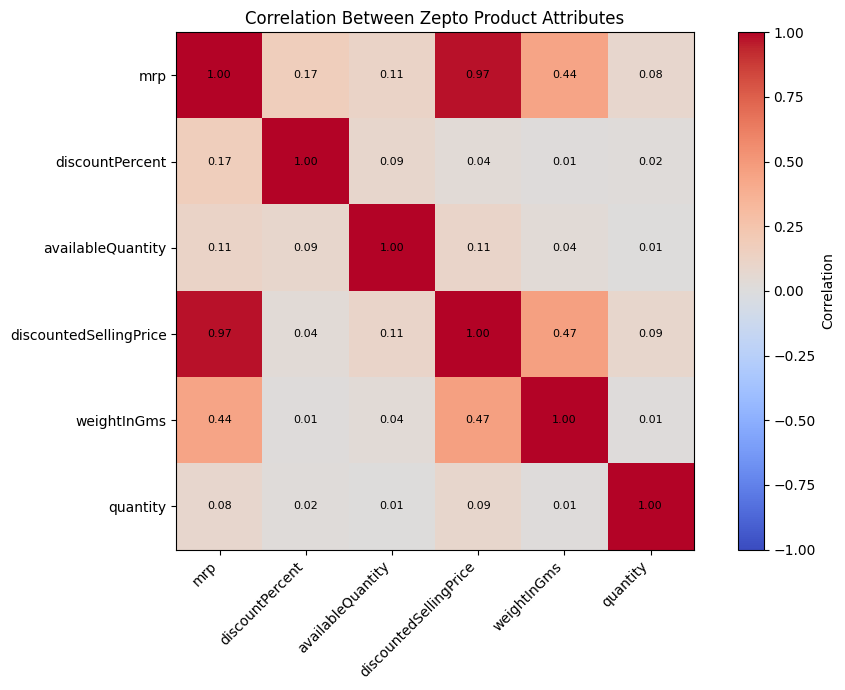

In [94]:
plt.figure(figsize=(10, 7))
plt.imshow(correlation_matrix,cmap="coolwarm",vmin=-1,vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)
# Display correlation values inside the chart
for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )
plt.title("Correlation Between Zepto Product Attributes")
plt.tight_layout()
plt.savefig(visualization_dir / "11_correlation_between_zepto_product_attributes.png", dpi=300, bbox_inches="tight")
plt.show()


# Calculate potential sales value using available quantity


In [95]:
df["potentialSalesValue"]=(df["discountedSellingPrice"]*df["availableQuantity"])
# Summarize by category
category_sales_analysis=(df.groupby("Category").agg(potential_sales_value=("potentialSalesValue","sum"),
        average_product_price=("discountedSellingPrice","mean"),total_products=("name","count")).sort_values(by="potential_sales_value",ascending=False
    )
)
print(category_sales_analysis.round(2))

                       potential_sales_value  average_product_price  \
Category                                                              
Cooking Essentials                  337369.0                 140.83   
Munchies                            337369.0                 140.83   
Paan Corner                         270039.0                 189.90   
Personal Care                       270039.0                 189.90   
Chocolates & Candies                224385.0                 141.08   
Ice Cream & Desserts                224385.0                 141.08   
Packaged Food                       224385.0                 141.08   
Home & Cleaning                     122661.0                 141.45   
Health & Hygiene                     64180.0                 145.86   
Beverages                            55051.0                 103.73   
Dairy, Bread & Batter                55051.0                 103.73   
Biscuits                             25007.6                  52.78   
Meats,

/var/folders/gl/b15p53412xxgy4jhd3vm5kbw0000gn/T/ipykernel_9825/3767510035.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["potentialSalesValue"]=(df["discountedSellingPrice"]*df["availableQuantity"])


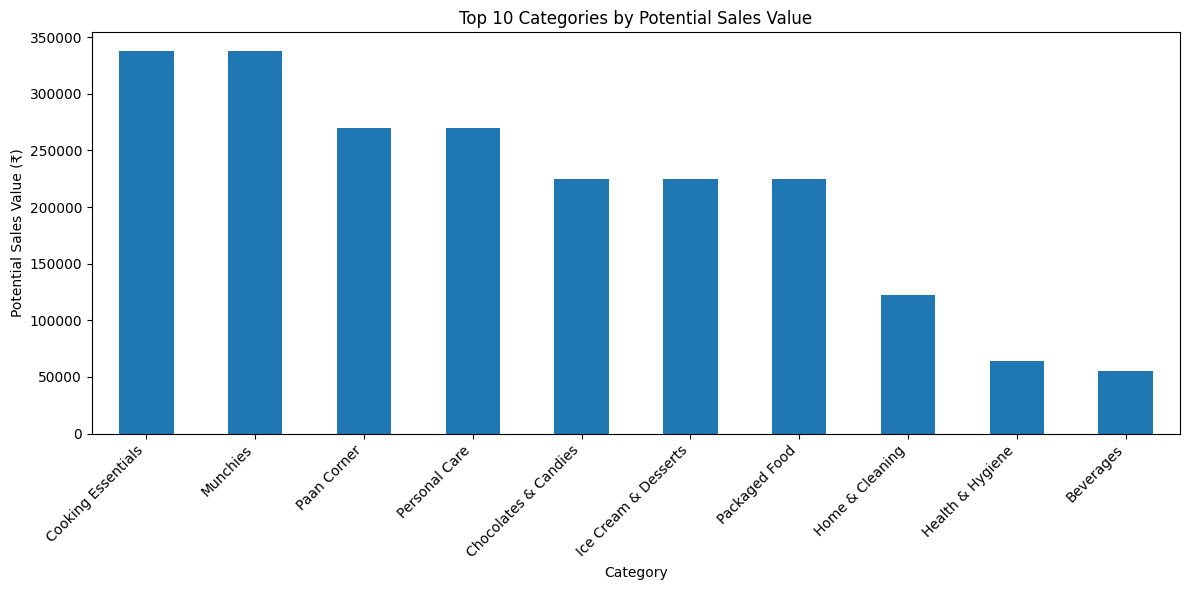

In [ ]:
top_10_categories = category_sales_analysis.head(10)
top_10_categories["potential_sales_value"].plot(kind="bar",figsize=(12, 6))
plt.title("Top 10 Categories by Potential Sales Value")
plt.xlabel("Category")
plt.ylabel("Potential Sales Value (₹)")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.savefig(visualization_dir / "12_top_10_categories_by_potential_sales_value.png", dpi=300, bbox_inches="tight")
plt.show()


In [100]:
product_scorecard=df.copy()
# Classify discount levels
product_scorecard["discountLevel"]=pd.cut(
    product_scorecard["discountPercent"],
    bins=[-1,10,30,100],
    labels=["Low Discount","Medium Discount","High Discount"]
)
# Classify price levels
product_scorecard["priceLevel"]=pd.cut(
    product_scorecard["discountedSellingPrice"],
    bins=[-0.01,100,500,1000,float("inf")],
    labels=["Budget","Mid-Range","Premium","Luxury"]
)
# Classify stock levels
product_scorecard["stockLevel"]=np.select(
    [
        product_scorecard["outOfStock"].eq(True),
        product_scorecard["availableQuantity"].le(10),
        product_scorecard["availableQuantity"].le(50)
    ],
    [
        "Out of Stock",
        "Low Stock",
        "Moderate Stock"
    ],
    default="High Stock"
)

print(
    product_scorecard[
        [
            "Category",
            "name",
            "discountPercent",
            "discountLevel",
            "discountedSellingPrice",
            "priceLevel",
            "availableQuantity",
            "stockLevel"
        ]
    ].head(15)
)

               Category              name  discountPercent    discountLevel  \
0   Fruits & Vegetables             Onion               16  Medium Discount   
1   Fruits & Vegetables     Tomato Hybrid               16  Medium Discount   
2   Fruits & Vegetables    Tender Coconut               15  Medium Discount   
3   Fruits & Vegetables  Coriander Leaves               15  Medium Discount   
4   Fruits & Vegetables    Ladies Finger                14  Medium Discount   
5   Fruits & Vegetables            Potato               17  Medium Discount   
6   Fruits & Vegetables             Lemon               16  Medium Discount   
7   Fruits & Vegetables       Watermelon                15  Medium Discount   
8   Fruits & Vegetables   Capsicum Green                17  Medium Discount   
9   Fruits & Vegetables     Chilli Green                15  Medium Discount   
10  Fruits & Vegetables    Banana Robusta               17  Medium Discount   
11  Fruits & Vegetables    Garlic Indian            

In [101]:
discount_summary=(product_scorecard["discountLevel"].value_counts())
stock_summary=(product_scorecard["stockLevel"].value_counts())
print("Discount Level Summary:")
print(discount_summary)
print("\nStock Level Summary:")
print(stock_summary)

Discount Level Summary:
discountLevel
Low Discount       2918
Medium Discount     725
High Discount        87
Name: count, dtype: int64

Stock Level Summary:
stockLevel
Low Stock       3277
Out of Stock     453
Name: count, dtype: int64


In [102]:
category_scorecard=(product_scorecard.groupby("Category").agg(average_discount=("discountPercent", "mean"),average_price=("discountedSellingPrice", "mean"),
        low_stock_products=("stockLevel",lambda x: (x == "Low Stock").sum()),out_of_stock_products=("outOfStock","sum"),total_products=("name", "count"))
        .sort_values("low_stock_products", ascending=False)
)
print(category_scorecard.round(2))

                       average_discount  average_price  low_stock_products  \
Category                                                                     
Cooking Essentials                 7.16         140.83                 450   
Munchies                           7.16         140.83                 450   
Chocolates & Candies               8.32         141.08                 343   
Ice Cream & Desserts               8.32         141.08                 343   
Packaged Food                      8.32         141.08                 343   
Paan Corner                        6.24         189.90                 322   
Personal Care                      6.24         189.90                 322   
Home & Cleaning                    5.68         141.45                 175   
Biscuits                           8.24          52.78                 105   
Beverages                          7.16         103.73                 101   
Dairy, Bread & Batter              7.16         103.73          

In [ ]:
category_scorecard=(product_scorecard.groupby("Category")
    .agg(
        average_discount=("discountPercent", "mean"),
        average_price=("discountedSellingPrice", "mean"),
        low_stock_products=(
            "stockLevel",
            lambda x: (x == "Low Stock").sum()
        ),
        out_of_stock_products=(
            "outOfStock",
            "sum"
        ),
        total_products=("name", "count")
    )
    .sort_values("low_stock_products", ascending=False)
)

print(category_scorecard.round(2))

                       average_discount  average_price  low_stock_products  \
Category                                                                     
Cooking Essentials                 7.16         140.83                 450   
Munchies                           7.16         140.83                 450   
Chocolates & Candies               8.32         141.08                 343   
Ice Cream & Desserts               8.32         141.08                 343   
Packaged Food                      8.32         141.08                 343   
Paan Corner                        6.24         189.90                 322   
Personal Care                      6.24         189.90                 322   
Home & Cleaning                    5.68         141.45                 175   
Biscuits                           8.24          52.78                 105   
Beverages                          7.16         103.73                 101   
Dairy, Bread & Batter              7.16         103.73          

In [ ]:
category_dashboard=(
    df.groupby("Category")
    .agg(
        total_products=("name", "count"),
        average_discount=("discountPercent", "mean"),
        average_selling_price=("discountedSellingPrice", "mean"),
        out_of_stock_count=("outOfStock", "sum"),
        average_available_quantity=("availableQuantity", "mean")
    )
)
category_dashboard["out_of_stock_rate"]=(category_dashboard["out_of_stock_count"]/category_dashboard["total_products"]*100)
category_dashboard = category_dashboard.sort_values(by="out_of_stock_rate",ascending=False)
print(category_dashboard.round(2))

                       total_products  average_discount  \
Category                                                  
Biscuits                          147              8.24   
Beverages                         129              7.16   
Dairy, Bread & Batter             129              7.16   
Meats, Fish & Eggs                 63             11.03   
Health & Hygiene                   97              8.05   
Cooking Essentials                514              7.16   
Munchies                          514              7.16   
Chocolates & Candies              388              8.32   
Ice Cream & Desserts              388              8.32   
Packaged Food                     388              8.32   
Home & Cleaning                   194              5.68   
Fruits & Vegetables                93             15.46   
Paan Corner                       343              6.24   
Personal Care                     343              6.24   

                       average_selling_price  out_of_st

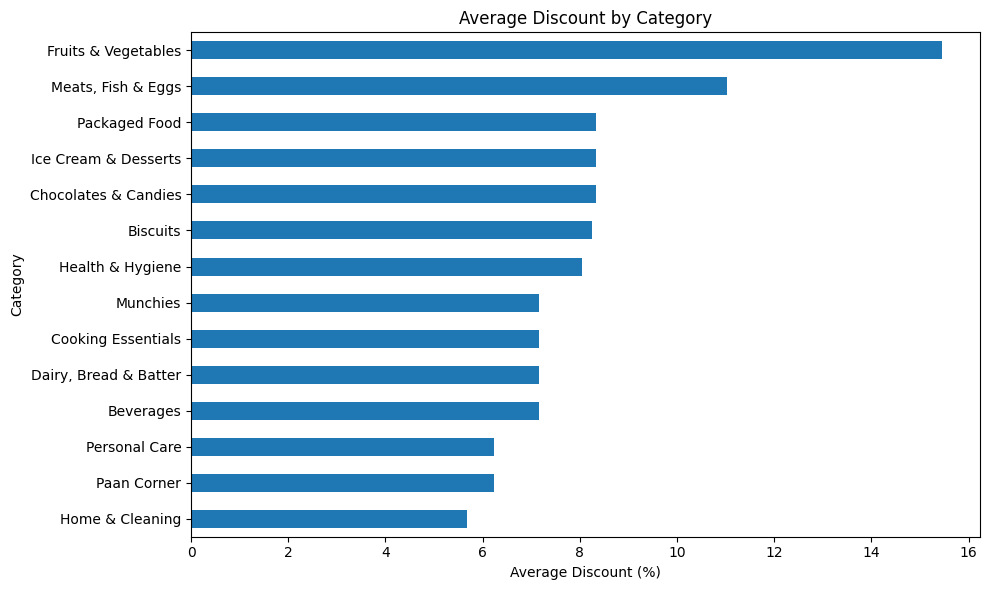

In [ ]:
category_dashboard["average_discount"].sort_values().plot(kind="barh",figsize=(10, 6))
plt.title("Average Discount by Category")
plt.xlabel("Average Discount (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(visualization_dir / "13_average_discount_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


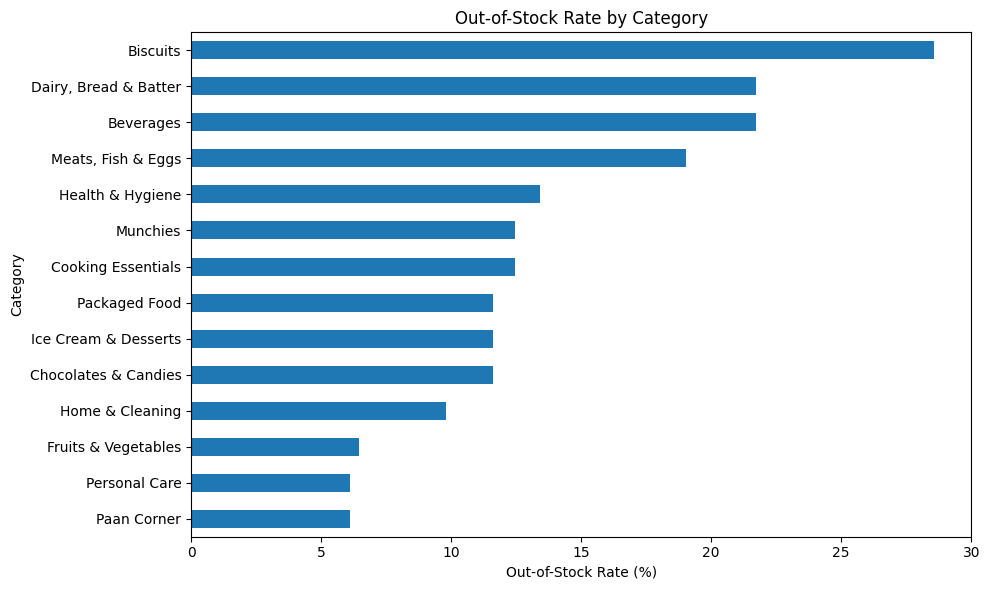

In [ ]:
category_dashboard["out_of_stock_rate"].sort_values().plot(kind="barh",figsize=(10, 6))
plt.title("Out-of-Stock Rate by Category")
plt.xlabel("Out-of-Stock Rate (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(visualization_dir / "14_out_of_stock_rate_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


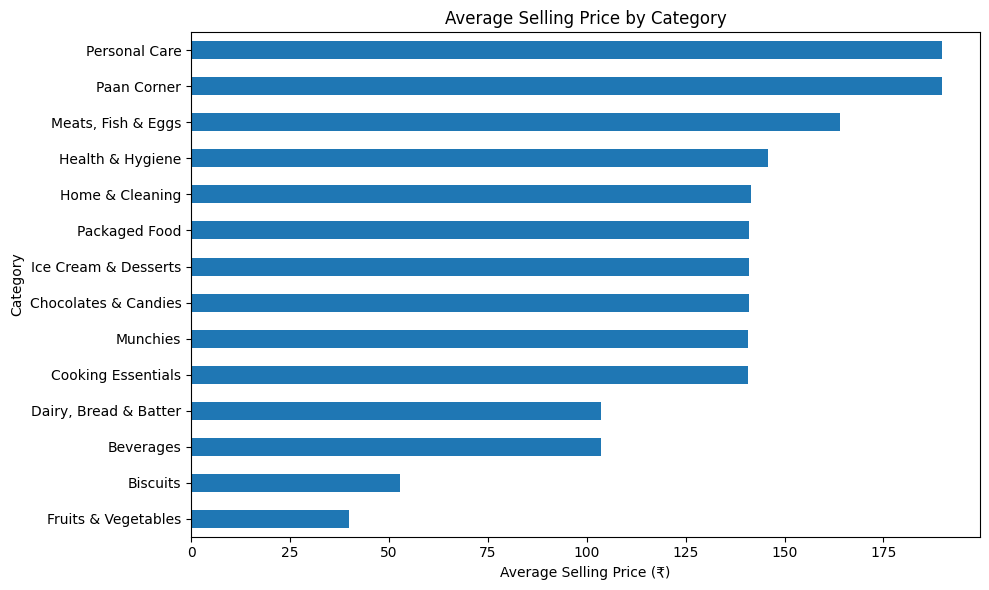

In [ ]:
category_dashboard["average_selling_price"].sort_values().plot(kind="barh",figsize=(10, 6))
plt.title("Average Selling Price by Category")
plt.xlabel("Average Selling Price (₹)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(visualization_dir / "15_average_selling_price_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
from pathlib import Path
output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)
category_dashboard.to_csv(output_path / "category_dashboard_summary.csv")
print("Dashboard summary saved successfully!")

Dashboard summary saved successfully!
